# Parametric VaR: Backtesting
**Validator:** Cassie Wan

**Project Specifications:** 1-day 99% VaR, $1M SPY portfolio

Exception occurs if P&L < -VaR: VaR in the output file is a positive dollar loss threshold and is dated to the day it forecasts so no further shifting is needed

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

PATH = '../../results/parametric_var_output.csv'
df = pd.read_csv(PATH, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)

df['Exception'] = (df.Portfolio_PnL < -df.VaR_99).astype(int)
df['Year'] = df.Date.dt.year

os.makedirs("../../results/validation/parametric/figures", exist_ok=True)

## Exception Analysis

In [6]:
P = 0.01
n = len(df); x = int(df.Exception.sum())
summary = pd.DataFrame({'Observations':[n], 'Expected exceptions':[n*P], 'Actual exceptions':[x], 'Exception rate':[x/n]})
display(summary)

annual = df.groupby('Year').agg(Obs=('Exception','size'), Actual=('Exception','sum'))
annual['Expected'] = annual.Obs * P
annual['Rate'] = annual.Actual / annual.Obs
display(annual)

exc = df.loc[df.Exception==1, ['Date','Portfolio_PnL','VaR_99','Rolling_Std']].copy()
exc['Loss / VaR'] = -exc.Portfolio_PnL / exc.VaR_99
display(exc.sort_values('Loss / VaR', ascending=False).head(15))
print('Mean loss/VaR on exception days: %.2f, max: %.2f' % (exc['Loss / VaR'].mean(), exc['Loss / VaR'].max()))

,Observations,Expected exceptions,Actual exceptions,Exception rate
0,3939,39.39,106,0.02691


,Obs,Actual,Expected,Rate
Year,,,,
2010,1,0,0.01,0.000000
2011,252,10,2.52,0.039683
2012,250,1,2.50,0.004000
2013,252,3,2.52,0.011905
2014,252,10,2.52,0.039683
2015,252,8,2.52,0.031746
2016,252,4,2.52,0.015873
2017,251,3,2.51,0.011952
2018,251,17,2.51,0.067729


,Date,Portfolio_PnL,VaR_99,Rolling_Std,Loss / VaR
1785,2018-02-05,-41822.472318,10035.156122,0.004637,4.167596
2310,2020-03-09,-78094.533719,22478.869881,0.009797,3.474131
2313,2020-03-12,-95677.212422,27614.975350,0.011859,3.464686
2315,2020-03-16,-109423.733848,33529.349255,0.014377,3.263521
151,2011-08-08,-65123.251166,20845.689491,0.009093,3.124063
1788,2018-02-08,-37508.872866,12181.422239,0.005499,3.079187
3586,2025-04-04,-58542.947643,21378.937559,0.009286,2.738347
3585,2025-04-03,-49280.804932,20039.946175,0.008774,2.459129
2303,2020-02-27,-44911.717496,18382.087169,0.008107,2.443233
149,2011-08-04,-46841.562971,19503.160972,0.008598,2.401742


Mean loss/VaR on exception days: 1.48, max: 4.17


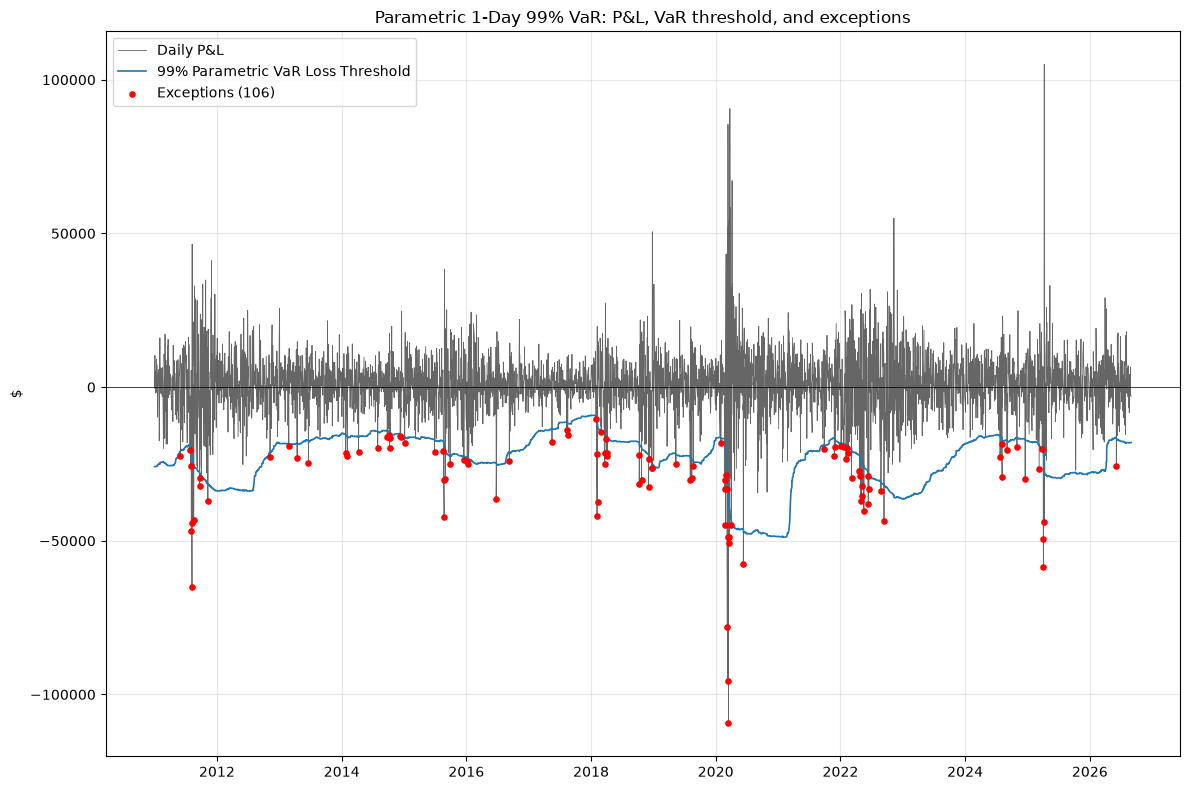

In [7]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(df.Date, df.Portfolio_PnL, color='black', lw=0.6, alpha=0.6, label='Daily P&L')
ax.plot(df.Date, -df.VaR_99, color='tab:blue', lw=1.2, label='99% Parametric VaR Loss Threshold')
e = df[df.Exception==1]
ax.scatter(e.Date, e.Portfolio_PnL, color='red', s=14, zorder=3, label=f'Exceptions ({len(e)})')
ax.axhline(0, color='black', lw=0.5); ax.grid(alpha=0.3)
ax.set_title('Parametric 1-Day 99% VaR: P&L, VaR threshold, and exceptions'); ax.set_ylabel('$'); ax.legend()
plt.tight_layout(); plt.savefig('../../results/validation/parametric/figures/parametric_exceptions.png', dpi=200); plt.show()

## Statistical Tests (Kupiec, Christoffersen)

In [8]:
def kupiec(n, x, p = P):
    p_hat = x / n
    ll0 = (n - x) * np.log(1-p) + x * np.log(p)
    ll1 = (n - x) * np.log(1-p_hat) + (x * np.log(p_hat) if x > 0 else 0)
    lr = -2 * (ll0-ll1)
    return lr, chi2.sf(lr, 1)

def christoffersen(e):
    a, b = e[:-1], e[1:]
    n00 = int(((a==0) & (b==0)).sum()); n01 = int(((a==0)&(b==1)).sum())
    n10 = int(((a==1)&(b==0)).sum()); n11 = int(((a==1)&(b==1)).sum())
    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11)
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll = lambda k, m, q: (k * np.log(q) if k > 0 else 0) + (m * np.log(1 - q) if m > 0 else 0)
    lr = -2 * (ll (n01 + n11, n00 + n10, pi) - (ll (n01, n00, pi01) + ll(n11, n10, pi11)))
    return (n00, n01, n10, n11), pi01, pi11, lr, chi2.sf(lr, 1)

lr_uc, p_uc = kupiec(n, x)
counts, pi01, pi11, lr_ind, p_ind = christoffersen(df.Exception.values)
lr_cc = lr_uc + lr_ind; p_cc = chi2.sf(lr_cc, 2)

tests = pd.DataFrame({
  'Test': ['Kupiec POF', 'Christoffersen Independence', 'Conditional coverage (UC + IND)'],
  'Test statistic': [lr_uc, lr_ind, lr_cc],
  'p-value': [p_uc, p_ind, p_cc],
  'Result at 5%': ['Reject' if p < 0.05 else 'Do not reject' for p in (p_uc, p_ind, p_cc)]})
display(tests)
print('Transition counts (00, 01, 10, 11):', counts)
print('P(exc | no exc yesterday) = %.4f ; P(exc | exc yesterday) = %.4f' % (pi01, pi11))

,Test,Test statistic,p-value,Result at 5%
0,Kupiec POF,77.788861,1.146650e-18,Reject
1,Christoffersen Independence,17.876250,2.357449e-05,Reject
2,Conditional coverage (UC + IND),95.665111,1.684942e-21,Reject


Transition counts (00, 01, 10, 11): (3738, 94, 94, 12)
P(exc | no exc yesterday) = 0.0245 ; P(exc | exc yesterday) = 0.1132


# Benchmarking

In [9]:
COMB = '../../results/combined_var_results.csv'
combined = pd.read_csv(COMB, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
check = combined.merge(df[['Date','VaR_99','Portfolio_PnL']], on='Date', suffixes=('','_p'))

assert len(check) == len(combined) == len(df)
assert (check.Parametric_VaR - check.VaR_99).abs().max() < 1e-6
assert (combined.Portfolio_PnL - 1e6*combined.SPY_Return).abs().max() < 1e-6
models = {'Historical':'Historical_VaR', 'Parametric':'Parametric_VaR', 'EWMA':'EWMA_VaR'}

In [10]:
rows = {}
for name, col in models.items():
    e = (combined.Portfolio_PnL < -combined[col]).astype(int)
    combined['E_'+name] = e
    nn, xx = len(combined), int(e.sum())
    lr_k, p_k = kupiec(nn, xx)
    cnt, a01, a11, lr_i, p_i = christoffersen(e.values)
    mult = (-combined.Portfolio_PnL[e==1] / combined.loc[e==1, col])
    rows[name] = {'Average VaR ($)': combined[col].mean(), 'Maximum VaR ($)': combined[col].max(),
                  'Actual exceptions': xx, 'Exception rate': xx/nn,
                  'Kupiec p-value': p_k, 'Christoffersen p-value': p_i,
                  'Mean loss / VaR on exceptions': mult.mean(), 'Max loss / VaR': mult.max()}
comparison = pd.DataFrame(rows)
display(comparison)
display(combined.groupby(combined.Date.dt.year)[['E_Historical','E_Parametric','E_EWMA']].sum())

,Historical,Parametric,EWMA
Average VaR ($),28603.448928,2.318773e+04,2.191504e+04
Maximum VaR ($),68076.174579,4.883790e+04,1.186772e+05
Actual exceptions,59.000000,1.060000e+02,9.100000e+01
Exception rate,0.014978,2.691038e-02,2.310231e-02
Kupiec p-value,0.003448,1.146650e-18,1.648372e-12
Christoffersen p-value,0.000021,2.357449e-05,5.841766e-03
Mean loss / VaR on exceptions,1.442881,1.478568e+00,1.423312e+00
Max loss / VaR,2.812955,4.167596e+00,3.392838e+00


,E_Historical,E_Parametric,E_EWMA
Date,,,
2010,0,0,0
2011,6,10,6
2012,1,1,5
2013,2,3,5
2014,3,10,10
2015,5,8,5
2016,1,4,2
2017,3,3,4
2018,7,17,8


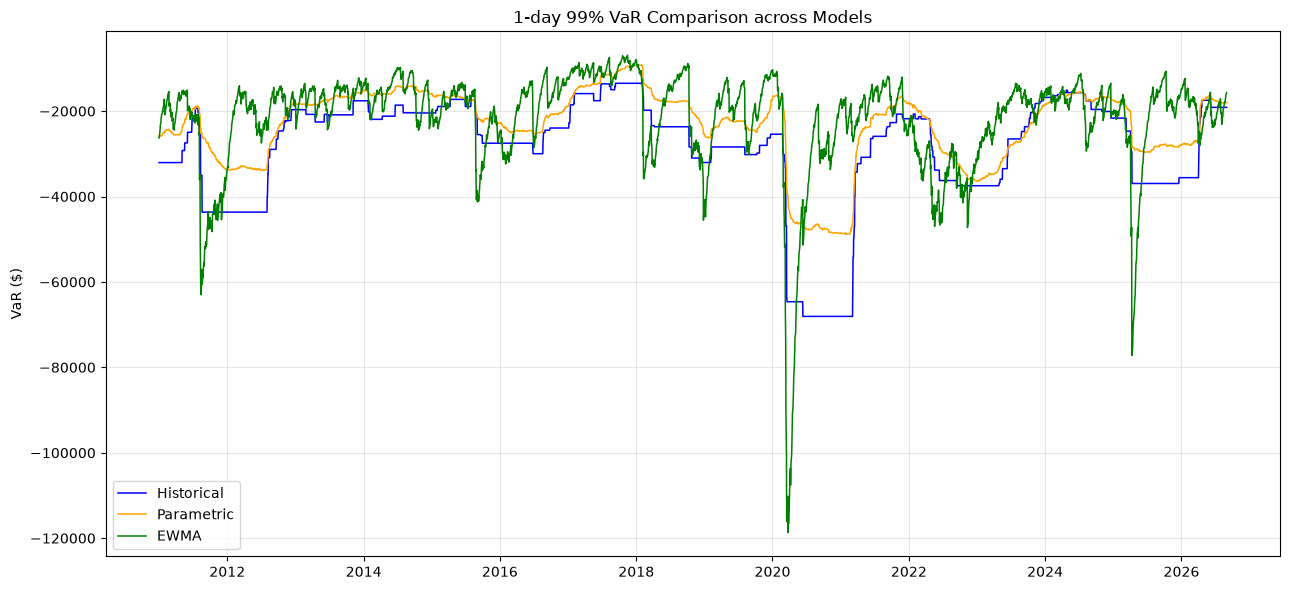

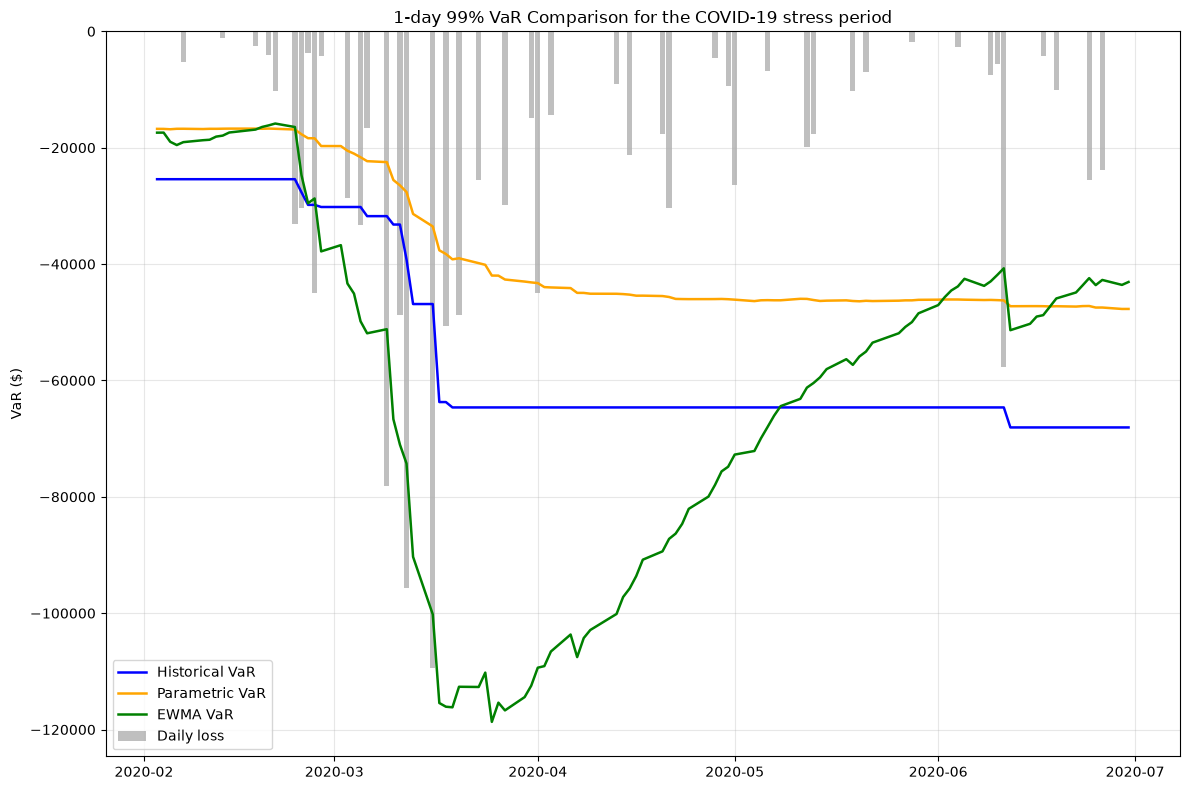

In [13]:
cols = {'Historical_VaR':('Historical','blue'), 'Parametric_VaR':('Parametric','orange'), 'EWMA_VaR':('EWMA','green')}
fig, ax = plt.subplots(figsize=(13,6))
for k,(n,col) in cols.items(): ax.plot(combined.Date, -combined[k], label=n, color=col, lw=1.1)
ax.set_title('1-day 99% VaR Comparison across Models'); ax.set_ylabel('VaR ($)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('../../results/validation/parametric/figures/var_comparison_full.png', dpi=200); plt.show()

w = combined[(combined.Date>='2020-02-01')&(combined.Date<='2020-06-30')]
fig, ax = plt.subplots(figsize=(12,8))
for k,(n,col) in cols.items(): ax.plot(w.Date, -w[k], label=n+' VaR', color=col, lw=1.8)
ax.bar(w.Date, w.Portfolio_PnL.clip(upper=0), color='black', alpha=.25, width=0.8, label='Daily loss')
ax.set_title('1-day 99% VaR Comparison for the COVID-19 stress period'); ax.set_ylabel('VaR ($)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('../../results/validation/parametric/figures/var_comparison_covid.png', dpi=200); plt.show()

In [12]:
base = combined[combined.Date=='2020-02-19'].iloc[0]
s = combined[(combined.Date>='2020-02-19')&(combined.Date<='2020-06-30')]
for k in models.values():
    print(k, s[s[k] >= 1.5*base[k]].Date.iloc[0].date(), '| Mar 16/Feb 19 ratio: %.2f' % (combined[combined.Date=='2020-03-16'][k].iloc[0]/base[k]))

Historical_VaR 2020-03-12 | Mar 16/Feb 19 ratio: 1.84
Parametric_VaR 2020-03-10 | Mar 16/Feb 19 ratio: 2.00
EWMA_VaR 2020-02-25 | Mar 16/Feb 19 ratio: 6.10
